In [1]:
from src import assemble_nodes
from src.orientation import get_angles, _correlate_angles, _make_rotating_masks
import numpy as np
import cv2 as cv
from matplotlib import pyplot as plt
from skimage.morphology import skeletonize
from mpl_toolkits.axes_grid1 import ImageGrid
from src.graph import Tree, ImageSegmentation
import torchvision.transforms as T
import torch
import os
from torchvision.io import read_image
from torch.utils.data import Dataset, random_split
from resource.branch_dataset.dataset import BranchData
import sys

In [2]:
dataset = BranchData(
    os.path.join("resource", "branch_dataset")
)

loader = torch.utils.data.DataLoader(
    dataset,
    batch_size=1,
    shuffle=True,
    num_workers=4
)

In [3]:
cnn = ImageSegmentation(kernel_size=3)
checkpoint = torch.load(os.path.join("model_checkpoints", f"checkpoint_nov_14_1chn_out_BCE.tar"))
cnn.load_state_dict(checkpoint["model_state_dict"])
cnn.eval();

In [4]:
accuracy = []
confidence = []
spot_check = {
    'original': [],
    'reconstruction': [],
    'accuracy': [],
    'confidence': [],
}

sys.setrecursionlimit(10000)

for batchid, (image, mask) in enumerate(loader, 0):
    model = Tree(image, cnn)
    approx = model.reconstruct_mask()

    e = np.abs(mask.squeeze(0).squeeze(0).numpy() - approx)
    s = np.sum(mask.squeeze(0).squeeze(0).numpy())
    a = 1 - (np.sum(e) / s)
    c = model.confidence
    
    accuracy.append(a)
    confidence.append(c)
    if batchid % 10 == 0:
        spot_check['original'].append(mask.squeeze(0).squeeze(0).numpy())
        spot_check['reconstruction'].append(approx)
        spot_check['accuracy'].append(a)
        spot_check['confidence'].append(c)

    print(f"Batch {batchid} accuracy {a}, confidence {c}")

c:\Users\wyatt\AppData\Local\Programs\Python\Python311\Lib\site-packages\torchvision\transforms\functional.py:1603: UserWarning: The default value of the antialias parameter of all the resizing transforms (Resize(), RandomResizedCrop(), etc.) will change from None to True in v0.17, in order to be consistent across the PIL and Tensor backends. To suppress this warning, directly pass antialias=True (recommended, future default), antialias=None (current default, which means False for Tensors and True for PIL), or antialias=False (only works on Tensors - PIL will still use antialiasing). This also applies if you are using the inference transforms from the models weights: update the call to weights.transforms(antialias=True).
  warnings.warn(


Batch 0 accuracy -0.5707062635508493, confidence -1.3828186489269736
Batch 1 accuracy -0.004511542787085876, confidence -10.5477180775274
Batch 2 accuracy -0.11855016570545707, confidence -1.5950665526789811
Batch 3 accuracy -0.033848079702959444, confidence -0.2760827950041355
Batch 4 accuracy -0.2982001474119689, confidence -1.648921474597359
Batch 5 accuracy 0.22886676875957124, confidence -1.1072741765228387
Batch 6 accuracy -0.25459183972007193, confidence -2.207957824131635
Batch 7 accuracy -0.04073691827704429, confidence -3.484833871435362
Batch 8 accuracy 0.42978429952850916, confidence -1.0310683736271158
Batch 9 accuracy -0.05714333004665195, confidence -1.0748561696314123
Batch 10 accuracy -0.006922999152142895, confidence -3.6068292032203533
Batch 11 accuracy 0.12277054734815462, confidence -0.6335950591506457
Batch 12 accuracy -0.7750105905874298, confidence -1.3201645402299917
Batch 13 accuracy -2.1921619698890247, confidence -4.605594525384474
Batch 14 accuracy 0.024972

MemoryError: 

In [11]:
import pickle
with open("test_results_dec_10.pickle", 'wb') as file:
    pickle.dump({
        'accuracy': accuracy,
        'confidence': confidence,
        'check': spot_check
    }, file)

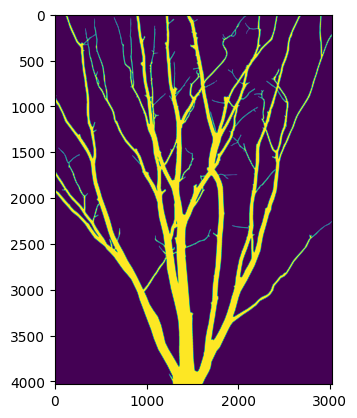

In [19]:
IDX = 10
plt.imshow(spot_check["original"][IDX])


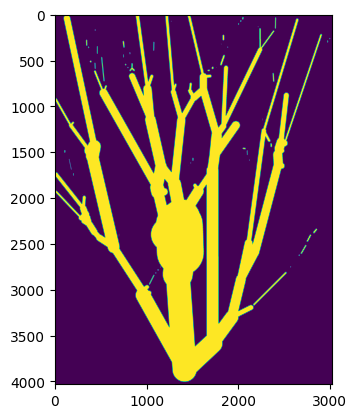

In [20]:
plt.imshow(spot_check["reconstruction"][IDX])

In [22]:
mean_acc = np.mean(accuracy)
mean_acc

-0.0006688349718524774

In [25]:
std_acc = np.std(accuracy)
std_acc

0.43707098457832205

In [23]:
max_acc = np.max(accuracy)
max_acc

0.7167008175887609

In [24]:
min_acc = np.min(accuracy)
min_acc

-2.9194822879773126

Text(0.5, 1.0, 'Reconstruction Accuracies')

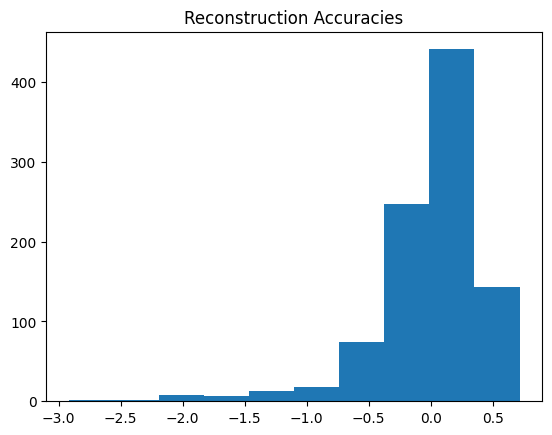

In [27]:
plt.hist( accuracy)
plt.title("Reconstruction Accuracies")

In [28]:
corr = np.corrcoef(accuracy, confidence)[1,0]
corr

0.00934958552854695

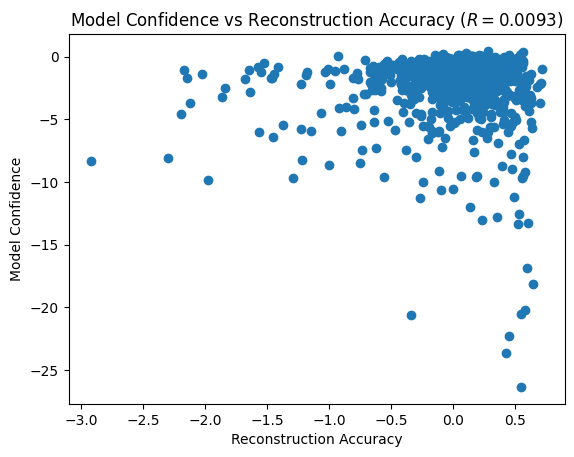

In [34]:
plt.scatter(accuracy, confidence)
plt.title(f"Model Confidence vs Reconstruction Accuracy ($R = {np.round(corr, 4)})$")
plt.xlabel("Reconstruction Accuracy")
plt.ylabel("Model Confidence")
plt.show()

In [35]:
print(f"Number of trials: {len(accuracy)}")

Number of trials: 953
